# Mô hình dự đoán độ ưu tiên công việc

Notebook này ghi lại toàn bộ quy trình học máy của FlowAgent: thu thập dữ liệu, tiền xử lý, phân tích khám phá (EDA), huấn luyện và so sánh mô hình, và kiểm tra khả năng áp dụng cho công việc viết bằng tiếng Việt.

Mục tiêu: khi người dùng tạo công việc mà không nói độ ưu tiên, hệ thống tự gợi ý một trong bốn mức `low`, `medium`, `high`, `urgent`.

In [1]:
import json
import os
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
os.chdir(ROOT)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import confusion_matrix

from flowagent.ml.embeddings import embed_texts, embed_texts_cached
from flowagent.ml.labels import JIRA_PRIORITY_TO_APP
from flowagent.ml.text_cleaning import build_issue_text
from flowagent.ml.train_priority_model import (
    EMBEDDING_CACHE_PATH,
    VIETNAMESE_EVAL_PATH,
    load_raw_issues,
)
from flowagent.ml.training import (
    CLASS_LABELS,
    build_embedding_classifier,
    build_majority_baseline,
    build_tfidf_classifier,
    prepare_dataset,
    score_predictions,
    split_dataset,
)

FIGURES = ROOT / "docs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
PALETTE = {"low": "#7FB77E", "medium": "#F2C14E", "high": "#F78154", "urgent": "#C0392B"}


def save_figure(name):
    plt.tight_layout()
    plt.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

E:\code\FlowAgent\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Thu thập dữ liệu (báo cáo mục 2.1)

Dữ liệu được thu thập từ **Apache Jira** (`issues.apache.org/jira`), hệ thống quản lý issue công khai của Apache Software Foundation, qua REST API không cần đăng nhập. Script `python -m flowagent.ml.jira_collection` lấy tối đa 3.000 issue **đã được xử lý** (resolved) mới nhất của 12 dự án mã nguồn mở lớn. Mỗi issue gồm tiêu đề, mô tả, loại issue, ngày tạo và **độ ưu tiên do người quản lý dự án gán** (nhãn thật, không phải nhãn tự đặt).

In [2]:
raw_issues = load_raw_issues(ROOT / "data/raw/apache_jira_issues.csv")
print(f"Số issue thu thập: {len(raw_issues):,}")
print(f"Khoảng thời gian: {raw_issues['created'].min()} → {raw_issues['created'].max()}")
raw_issues.groupby("project").size().rename("số issue").to_frame().T

Số issue thu thập: 36,000
Khoảng thời gian: 2009-04-10 → 2026-10-13


project,CAMEL,CASSANDRA,FLINK,HADOOP,HBASE,HIVE,IGNITE,KAFKA,NIFI,SOLR,SPARK,ZOOKEEPER
số issue,3000,3000,3000,3000,3000,3000,3000,3000,3000,3000,3000,3000


In [3]:
raw_issues["priority"].value_counts().rename("số issue").to_frame().T

priority,Major,Minor,Normal,Blocker,Critical,Trivial,Low,Urgent,High,Not a Priority
số issue,23989,6344,2808,1253,834,563,110,46,36,17


## 2. Tiền xử lý (báo cáo mục 3.1)

1. **Quy đổi nhãn**: các dự án Apache dùng nhiều thang ưu tiên khác nhau (Blocker…Trivial, P0…P4, High/Low). Tất cả được quy về 4 mức của FlowAgent; nhãn không dùng được (ví dụ `Not a Priority`) bị loại.
2. **Làm sạch văn bản**: bỏ khối mã `{code}`, `{noformat}`, dòng stack trace, URL và cú pháp wiki của Jira; gộp tiêu đề với 300 ký tự đầu của mô tả.
3. **Loại bỏ** văn bản quá ngắn (dưới 10 ký tự) và bản trùng lặp.

In [4]:
mapping = pd.DataFrame(
    [(jira, app.value) for jira, app in JIRA_PRIORITY_TO_APP.items()],
    columns=["Nhãn Jira", "Nhãn FlowAgent"],
)
mapping.groupby("Nhãn FlowAgent")["Nhãn Jira"].apply(", ".join).reindex(CLASS_LABELS).to_frame()

,Nhãn Jira
Nhãn FlowAgent,
low,"Minor, Low, Trivial, P3, P4"
medium,"Major, Normal, P2"
high,"Critical, High, P1"
urgent,"Blocker, Urgent, P0"


In [5]:
has_code_block = raw_issues["description"].fillna("").str.contains("{code", regex=False)
example = raw_issues[has_code_block].iloc[0]
print("TRƯỚC:\n", (example["summary"] + "\n" + example["description"])[:600])
print("\nSAU:\n", build_issue_text(example["summary"], example["description"]))

TRƯỚC:
 The ProducerFailureHandlingTest#testCannotSendToInternalTopic test case is flaky
 

This test case is flaky i.e.,
{code:java}
Gradle Test Run :clients:clients-integration-tests:test > Gradle Test Executor 120 > ProducerFailureHandlingTest > testCannotSendToInternalTopic(ClusterInstance) > testCannotSendToInternalTopic [3] Type=Raft-Isolated, MetadataVersion=4.3-IV0,BrokerSecurityProtocol=PLAINTEXT,BrokerListenerName=ListenerName(EXTERNAL),ControllerSecurityProtocol=PLAINTEXT,ControllerListenerName=ListenerName(CONTROLLER) FAILED
      java.lang.AssertionError: Assertion failed with an exc

SAU:
 The ProducerFailureHandlingTest testCannotSendToInternalTopic test case is flaky. This test case is flaky i.e., Related run I also checked develocity and it seems it failed multiple times Sep 25 and Sep 28. We should fix it.


In [6]:
dataset = prepare_dataset(raw_issues)
print(
    f"Còn lại sau tiền xử lý: {len(dataset):,} / {len(raw_issues):,} issue ({len(dataset) / len(raw_issues):.1%})"
)

Còn lại sau tiền xử lý: 35,795 / 36,000 issue (99.4%)


## 3. Phân tích khám phá dữ liệu – EDA (báo cáo mục 3.2)

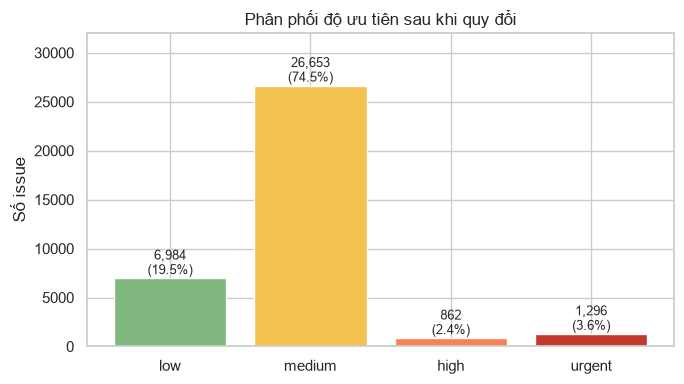

In [7]:
label_counts = dataset["label"].value_counts().reindex(CLASS_LABELS)
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(CLASS_LABELS, label_counts, color=[PALETTE[label] for label in CLASS_LABELS])
for bar, count in zip(bars, label_counts, strict=True):
    ax.annotate(
        f"{count:,}\n({count / len(dataset):.1%})",
        (bar.get_x() + bar.get_width() / 2, count),
        ha="center",
        va="bottom",
        fontsize=9,
    )
ax.set_title("Phân phối độ ưu tiên sau khi quy đổi")
ax.set_ylabel("Số issue")
ax.set_ylim(0, label_counts.max() * 1.2)
save_figure("ml_01_label_distribution")

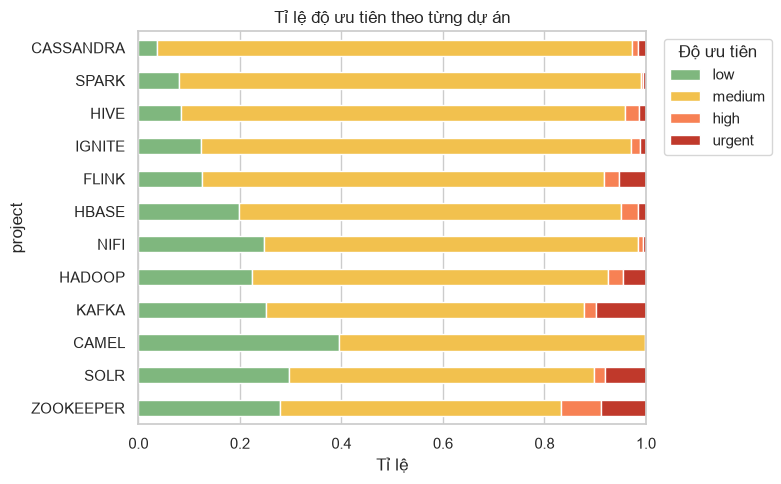

In [8]:
by_project = pd.crosstab(dataset["project"], dataset["label"], normalize="index")[CLASS_LABELS]
by_project = by_project.sort_values("medium")
ax = by_project.plot(
    kind="barh", stacked=True, figsize=(8, 5), color=[PALETTE[label] for label in CLASS_LABELS]
)
ax.set_title("Tỉ lệ độ ưu tiên theo từng dự án")
ax.set_xlabel("Tỉ lệ")
ax.legend(title="Độ ưu tiên", bbox_to_anchor=(1.02, 1), loc="upper left")
save_figure("ml_02_priority_by_project")

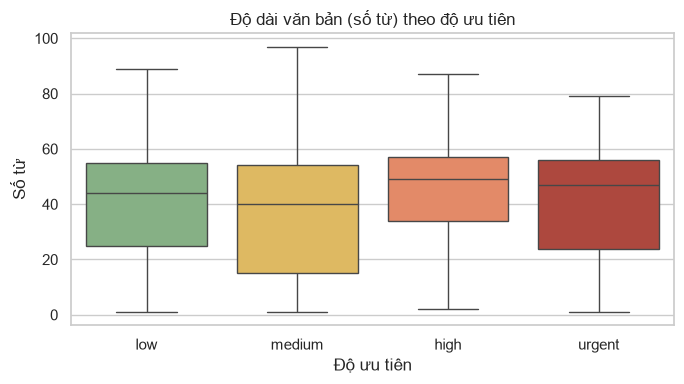

,mean,50%,max
label,,,
low,39.8,44.0,89.0
medium,35.9,40.0,97.0
high,44.5,49.0,87.0
urgent,40.5,47.0,79.0


In [9]:
dataset = dataset.assign(word_count=dataset["text"].str.split().str.len())
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(
    data=dataset,
    x="label",
    y="word_count",
    order=CLASS_LABELS,
    hue="label",
    palette=PALETTE,
    showfliers=False,
    legend=False,
    ax=ax,
)
ax.set_title("Độ dài văn bản (số từ) theo độ ưu tiên")
ax.set_xlabel("Độ ưu tiên")
ax.set_ylabel("Số từ")
save_figure("ml_03_text_length")
dataset.groupby("label")["word_count"].describe().reindex(CLASS_LABELS)[
    ["mean", "50%", "max"]
].round(1)

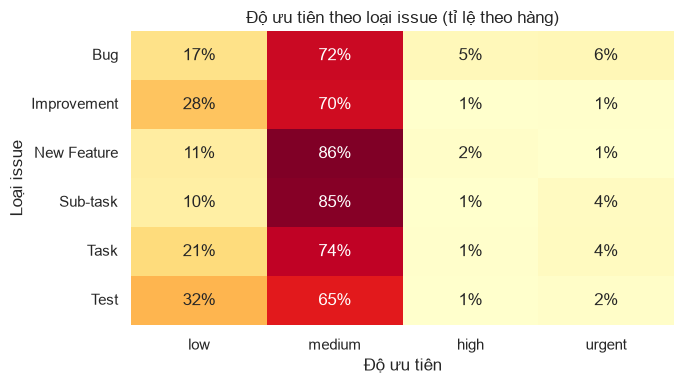

In [10]:
top_types = dataset["issue_type"].value_counts().head(6).index
common_types = dataset[dataset["issue_type"].isin(top_types)]
type_table = pd.crosstab(common_types["issue_type"], common_types["label"], normalize="index")[
    CLASS_LABELS
]
fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(type_table, annot=True, fmt=".0%", cmap="YlOrRd", cbar=False, ax=ax)
ax.set_title("Độ ưu tiên theo loại issue (tỉ lệ theo hàng)")
ax.set_xlabel("Độ ưu tiên")
ax.set_ylabel("Loại issue")
save_figure("ml_04_issue_type_heatmap")

**Nhận xét EDA**: dữ liệu **mất cân bằng mạnh**, `medium` chiếm đa số còn `urgent` rất ít. Vì vậy (1) độ đo chính là **macro-F1** (trung bình F1 của 4 lớp, không bị lớp đông áp đảo) và (2) các mô hình dùng `class_weight="balanced"`. Tỉ lệ ưu tiên khác nhau rõ giữa các dự án và giữa các loại issue, cho thấy cách gán nhãn phụ thuộc một phần vào thói quen của từng nhóm phát triển, đây là giới hạn trên tự nhiên của bài toán.

## 4. Xây dựng mô hình (báo cáo mục 3.3)

Chia dữ liệu **80% huấn luyện / 20% kiểm tra**, phân tầng theo nhãn, seed cố định. So sánh 3 mô hình:

| Mô hình | Đặc trưng | Bộ phân loại |
|---|---|---|
| Baseline | Không có | Luôn đoán lớp phổ biến nhất |
| TF-IDF + LR | TF-IDF từ đơn và cặp từ (tối đa 50.000 đặc trưng) | Logistic Regression cân bằng lớp |
| Embedding + LR | Vector câu 384 chiều từ `paraphrase-multilingual-MiniLM-L12-v2` (đa ngôn ngữ, hỗ trợ tiếng Việt) | Logistic Regression cân bằng lớp |

In [11]:
train_set, test_set = split_dataset(dataset)
print(f"Huấn luyện: {len(train_set):,} | Kiểm tra: {len(test_set):,}")

baseline = build_majority_baseline().fit(train_set["text"], train_set["label"])
tfidf_model = build_tfidf_classifier().fit(train_set["text"], train_set["label"])

embeddings = embed_texts_cached(dataset["text"].tolist(), ROOT / EMBEDDING_CACHE_PATH)
positions = {index: position for position, index in enumerate(dataset.index)}
train_embeddings = embeddings[[positions[index] for index in train_set.index]]
test_embeddings = embeddings[[positions[index] for index in test_set.index]]
embedding_model = build_embedding_classifier().fit(train_embeddings, train_set["label"])

predictions = {
    "Baseline (lớp đông nhất)": list(baseline.predict(test_set["text"])),
    "TF-IDF + LR": list(tfidf_model.predict(test_set["text"])),
    "Embedding đa ngôn ngữ + LR": list(embedding_model.predict(test_embeddings)),
}
scores = {
    name: score_predictions(test_set["label"], predicted) for name, predicted in predictions.items()
}
results = pd.DataFrame(
    {
        name: {"Accuracy": s.accuracy, "Macro-F1": s.macro_f1, "Weighted-F1": s.weighted_f1}
        for name, s in scores.items()
    }
).T.round(3)
results

Huấn luyện: 28,636 | Kiểm tra: 7,159


,Accuracy,Macro-F1,Weighted-F1
Baseline (lớp đông nhất),0.745,0.213,0.636
TF-IDF + LR,0.629,0.410,0.659
Embedding đa ngôn ngữ + LR,0.428,0.306,0.494


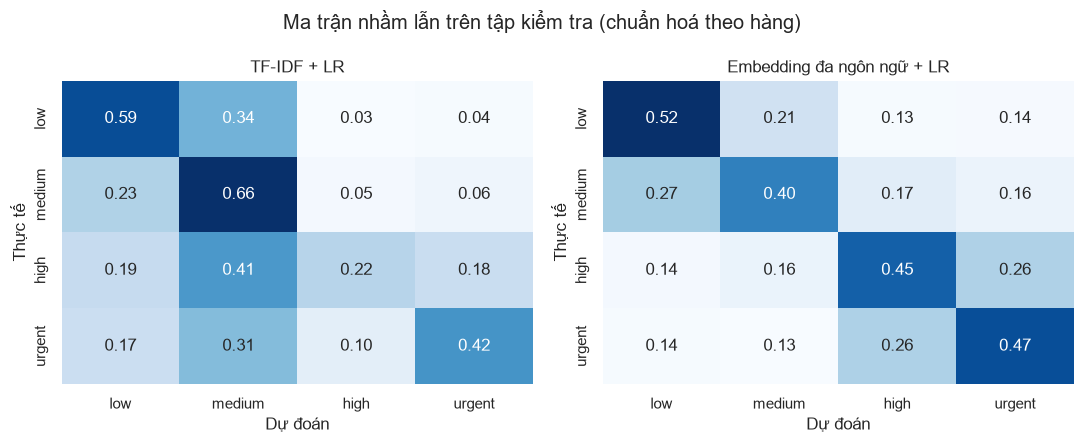

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name in zip(axes, ["TF-IDF + LR", "Embedding đa ngôn ngữ + LR"], strict=True):
    matrix = confusion_matrix(
        test_set["label"], predictions[name], labels=CLASS_LABELS, normalize="true"
    )
    sns.heatmap(
        matrix,
        annot=True,
        fmt=".2f",
        cmap="Blues",
        xticklabels=CLASS_LABELS,
        yticklabels=CLASS_LABELS,
        cbar=False,
        ax=ax,
    )
    ax.set_title(name)
    ax.set_xlabel("Dự đoán")
    ax.set_ylabel("Thực tế")
fig.suptitle("Ma trận nhầm lẫn trên tập kiểm tra (chuẩn hoá theo hàng)")
save_figure("ml_05_confusion_matrices")

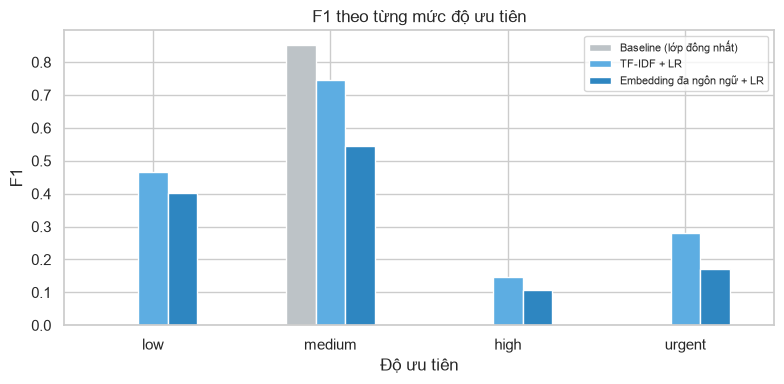

,Baseline (lớp đông nhất),TF-IDF + LR,Embedding đa ngôn ngữ + LR
low,0.000,0.467,0.402
medium,0.854,0.745,0.546
high,0.000,0.145,0.107
urgent,0.000,0.282,0.170


In [13]:
per_class = pd.DataFrame({name: s.per_class_f1 for name, s in scores.items()}).reindex(CLASS_LABELS)
ax = per_class.plot(kind="bar", figsize=(8, 4), rot=0, color=["#BDC3C7", "#5DADE2", "#2E86C1"])
ax.set_title("F1 theo từng mức độ ưu tiên")
ax.set_ylabel("F1")
ax.set_xlabel("Độ ưu tiên")
ax.legend(loc="upper right", fontsize=8)
save_figure("ml_06_per_class_f1")
per_class.round(3)

In [14]:
vectorizer = tfidf_model.named_steps["tfidf"]
classifier = tfidf_model.named_steps["classifier"]
vocabulary = np.array(vectorizer.get_feature_names_out())
pd.DataFrame(
    {
        label: vocabulary[np.argsort(classifier.coef_[index])[-10:][::-1]]
        for index, label in enumerate(classifier.classes_)
    }
)[CLASS_LABELS]

,low,medium,high,urgent
0,camel,cassandra,harry,release
1,typo,currently,server,release testing
2,typos,support,when,kraft
3,test,website,disable,solr
4,use,improve,job,testing
5,warning,ignite,zookeeper,license
6,unnecessary,add,follower,blocker
7,unused,bump,observed,new
8,metrics,accord,ghsa,kip
9,documentation,calcite,journal,search


Bảng trên là **10 từ hoặc cụm từ có trọng số cao nhất** của mô hình TF-IDF cho mỗi mức, giúp giải thích mô hình đã học được gì từ dữ liệu.

## 5. Kiểm tra trên công việc tiếng Việt

Người dùng FlowAgent nhập công việc bằng **tiếng Việt**, trong khi dữ liệu huấn luyện là tiếng Anh. Bộ `datasets/vietnamese_tasks_labeled.csv` gồm 64 công việc tự gán nhãn (16 câu mỗi mức), chia 2 nhóm:
- `software`: công việc phần mềm, **cùng lĩnh vực** với dữ liệu huấn luyện.
- `personal`: công việc cá nhân, **khác lĩnh vực**, để đo mức độ chuyển giao.

Đây là bộ nhỏ do tác giả tự gán nhãn, chỉ dùng để đánh giá khả năng chuyển giao, không thay thế tập kiểm tra chính.

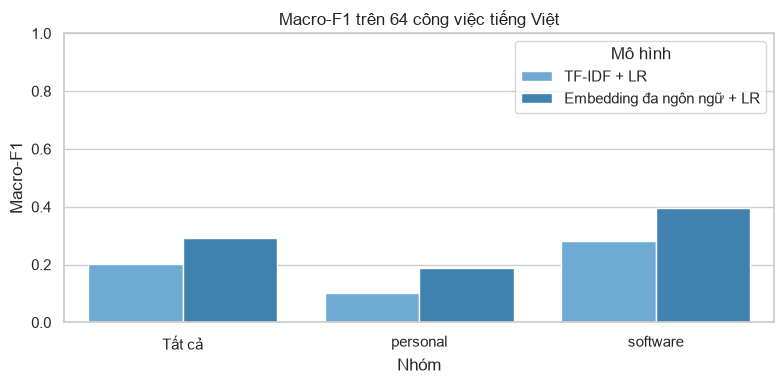

Mô hình,Embedding đa ngôn ngữ + LR,TF-IDF + LR
Nhóm,,
Tất cả,0.293,0.203
personal,0.188,0.100
software,0.397,0.283


In [15]:
vietnamese_tasks = pd.read_csv(ROOT / VIETNAMESE_EVAL_PATH)
vietnamese_tasks = vietnamese_tasks.assign(
    tfidf=tfidf_model.predict(vietnamese_tasks["text"]),
    embedding=embedding_model.predict(embed_texts(vietnamese_tasks["text"].tolist())),
)
transfer_rows = []
for domain, group in [("Tất cả", vietnamese_tasks), *vietnamese_tasks.groupby("domain")]:
    for model_name, column in [
        ("TF-IDF + LR", "tfidf"),
        ("Embedding đa ngôn ngữ + LR", "embedding"),
    ]:
        s = score_predictions(group["label"], list(group[column]))
        transfer_rows.append(
            {"Nhóm": domain, "Mô hình": model_name, "Accuracy": s.accuracy, "Macro-F1": s.macro_f1}
        )
transfer = pd.DataFrame(transfer_rows)
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(
    data=transfer, x="Nhóm", y="Macro-F1", hue="Mô hình", palette=["#5DADE2", "#2E86C1"], ax=ax
)
ax.set_title("Macro-F1 trên 64 công việc tiếng Việt")
ax.set_ylim(0, 1)
save_figure("ml_07_vietnamese_transfer")
transfer.pivot(index="Nhóm", columns="Mô hình", values="Macro-F1").round(3)

In [16]:
vietnamese_tasks[["text", "domain", "label", "tfidf", "embedding"]].sample(12, random_state=1)

,text,domain,label,tfidf,embedding
24,Sửa lỗi chính tả trong trang giới thiệu,software,low,medium,low
39,Gia hạn hộ chiếu đã hết hạn trước chuyến bay n...,personal,urgent,medium,urgent
52,Học thêm 20 từ vựng tiếng Anh,personal,medium,medium,low
27,Căn lề lại tiêu đề bảng trong trang quản trị,software,low,medium,low
44,Trả lời email của nhà tuyển dụng về lịch phỏng...,personal,high,medium,low
2,Lộ mật khẩu cơ sở dữ liệu trên kho mã công khai,software,urgent,medium,medium
21,Tối ưu lại cấu hình bộ nhớ đệm cho trang chủ,software,medium,medium,medium
62,Sắp xếp lại giá sách,personal,low,medium,medium
41,Hoàn thành báo cáo thực tập nộp cho công ty và...,personal,high,medium,low
50,Đọc xong chương 3 cuốn sách lập trình,personal,medium,medium,low


In [17]:
summary = {
    "dataset": {
        "collected": len(raw_issues),
        "usable": len(dataset),
        "train": len(train_set),
        "test": len(test_set),
        "label_counts": label_counts.to_dict(),
    },
    "apache_test": results.to_dict(orient="index"),
    "apache_test_per_class_f1": per_class.round(3).to_dict(),
    "vietnamese_transfer": transfer.round(3).to_dict(orient="records"),
}
(ROOT / "docs" / "ml_results.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8"
)
print(json.dumps(summary, ensure_ascii=False, indent=2))

{
  "dataset": {
    "collected": 36000,
    "usable": 35795,
    "train": 28636,
    "test": 7159,
    "label_counts": {
      "low": 6984,
      "medium": 26653,
      "high": 862,
      "urgent": 1296
    }
  },
  "apache_test": {
    "Baseline (lớp đông nhất)": {
      "Accuracy": 0.745,
      "Macro-F1": 0.213,
      "Weighted-F1": 0.636
    },
    "TF-IDF + LR": {
      "Accuracy": 0.629,
      "Macro-F1": 0.41,
      "Weighted-F1": 0.659
    },
    "Embedding đa ngôn ngữ + LR": {
      "Accuracy": 0.428,
      "Macro-F1": 0.306,
      "Weighted-F1": 0.494
    }
  },
  "apache_test_per_class_f1": {
    "Baseline (lớp đông nhất)": {
      "low": 0.0,
      "medium": 0.854,
      "high": 0.0,
      "urgent": 0.0
    },
    "TF-IDF + LR": {
      "low": 0.467,
      "medium": 0.745,
      "high": 0.145,
      "urgent": 0.282
    },
    "Embedding đa ngôn ngữ + LR": {
      "low": 0.402,
      "medium": 0.546,
      "high": 0.107,
      "urgent": 0.17
    }
  },
  "vietnamese_transfe

## 6. Kết luận và hạn chế

- **Trên tập kiểm tra tiếng Anh**, TF-IDF + LR tốt nhất (macro-F1 ≈ 0,41), gần gấp đôi baseline (≈ 0,21): văn bản có chứa tín hiệu về độ ưu tiên. Tuy vậy bài toán khó, vì nhãn do con người gán chủ quan, khác nhau giữa các dự án, và hai lớp `high`/`urgent` rất ít dữ liệu.
- **Embedding đa ngôn ngữ + LR** kém hơn trên tiếng Anh (≈ 0,31) nhưng là mô hình **duy nhất dùng được cho tiếng Việt**: trên nhóm công việc phần mềm đạt ≈ 0,40 so với ≈ 0,28 của TF-IDF (TF-IDF không có từ vựng tiếng Việt nên gần như đoán một lớp).
- **Với công việc cá nhân**, cả hai mô hình gần như không chuyển giao được (≈ 0,19 và ≈ 0,10, dưới mức đoán ngẫu nhiên 0,25). Khái niệm "khẩn cấp" trong issue phần mềm (sập hệ thống, lỗ hổng bảo mật) khác hẳn đời sống (cấp cứu, hạn nộp hồ sơ).
- **Quyết định thiết kế**: FlowAgent dùng mô hình Embedding + LR với tham số mặc định (không tinh chỉnh trên bộ tiếng Việt để tránh đánh giá lạc quan giả), và chỉ dùng kết quả như **gợi ý kèm độ tin cậy** khi người dùng không nói độ ưu tiên. Độ ưu tiên người dùng nói rõ luôn được ưu tiên.
- **Hướng cải thiện**: bổ sung dữ liệu công việc cá nhân tiếng Việt (thu thập từ người dùng hoặc sinh tổng hợp bằng LLM rồi kiểm duyệt) để thích nghi miền; thử encoder lớn hơn như `paraphrase-multilingual-mpnet-base-v2`.